#Tratamiento de datos Categoricos

Los datos categóricos en aprendizaje automático se refieren a variables que representan grupos o categorías distintas, como género, país o tipo de producto. Estos valores no son numéricos pero tienen un significado significativo en modelos basados en datos. El manejo de datos categóricos en aprendizaje automático es esencial porque los algoritmos requieren entradas numéricas para un entrenamiento y predicción efectivos.

Los datos categóricos en aprendizaje automático se refieren a variables que representan categorías o grupos distintos en lugar de valores numéricos. A diferencia de los datos numéricos, que pueden medirse y compararse matemáticamente, los datos categóricos describen atributos cualitativos de un conjunto de datos. El manejo de datos categóricos en aprendizaje automático es crucial porque la mayoría de los algoritmos funcionan mejor con entradas numéricas. Sin un preprocesamiento adecuado, los modelos pueden malinterpretar estas variables, lo que lleva a predicciones inexactas.

Tipos de datos categóricos:

**Datos nominales**

  Categorías sin orden inherente.

  Ejemplos: género (masculino, femenino), color (rojo, azul, verde), tipo de producto.

  El manejo de datos nominales en aprendizaje automático suele implicar métodos de codificación como la codificación one-hot.

**Datos ordinales**

  Categorías con un orden o ranking claro.

  Ejemplos: Nivel educativo (Bachillerato < Grado < Máster), Calificaciones (Baja < Media < Excelente).

  Al manejar datos categóricos en aprendizaje automático, los datos ordinales pueden codificarse numéricamente manteniendo el orden de las categorías.

https://www.upgrad.com/blog/categorical-data-in-machine-learning/

**Un manejo adecuado de los datos categóricos mejora la precisión del modelo, reduce el sesgo y garantiza mejores predicciones.**

**Paso 1 Identificar y analizar características categóricas**

El primer paso para manejar datos categóricos en aprendizaje automático es identificar qué columnas son categóricas. Los indicadores comunes incluyen:

Columnas con valores de texto/cadena (por ejemplo, Género, País)
Columnas con un conjunto limitado de valores únicos

Características ordinales con rango claro


**Herramientas para la identificación:**

Pandas .dtype y .unique() en Python

**Mejores prácticas para el análisis:**

Comprueba el número de categorías únicas (cardinalidad) para cada característica.

Analizar la distribución de categorías para detectar desequilibrios.

Visualiza datos categóricos con gráficos de barras o gráficos de conteo para entender patrones.


**Paso 2 Manejar valores ausentes o inconsistentes**

Antes de codificar, es esencial limpiar datos categóricos. Los valores ausentes o inconsistentes pueden distorsionar el entrenamiento del modelo si no se abordan correctamente.

**Estrategias habituales:**

Imputación: Sustituye los valores que faltan por la categoría más frecuente o una etiqueta especial como "Desconocido".

Comprobaciones de consistencia: Estandariza las variaciones (por ejemplo, "NY" frente a "Nueva York") para evitar categorías duplicadas.

Eliminación: En casos raros, se eliminan filas o columnas con valores excesivamente ausentes.


**Paso 3 Codificar datos categóricos para modelos de aprendizaje automático**

Codificar datos categóricos es el paso más crucial para manejar datos categóricos en aprendizaje automático. La codificación convierte los datos de texto o etiquetas en valores numéricos para que los algoritmos puedan procesarlos. La elección del método de codificación depende de:

Tipo de datos categóricos (nominales u ordinales)

Cardinalidad (número de categorías únicas)

El tipo de modelo de aprendizaje automático utilizado

**Resumen de los métodos de codificación más comunes:**

*   Codificación de etiquetas

*   Codificación One-Hot

*   Codificación ordinal

*   Codificación binaria/hash

*   Codificación de Destino/Frecuencia

Este paso garantiza que los datos categóricos se transformen correctamente, permitiendo que los modelos aprendan patrones de forma eficaz sin introducir sesgos.

1. Codificación de etiquetas

La codificación de etiquetas es una técnica que asigna un entero único a cada categoría en una característica categórica. Es especialmente útil para variables ordinales, donde las categorías tienen un orden significativo. Por ejemplo, los niveles educativos como Grado, Máster y Doctorado pueden representarse como 0, 1 y 2.

Caso de uso: Datos ordinales con orden inherente.

Explicación: Cada nivel educativo se convierte en un código numérico, manteniendo el orden natural de las categorías.

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

df = pd.DataFrame({'Education': ['Bachelor', 'Master', 'PhD', 'Master']})
le = LabelEncoder()
df['Education_encoded'] = le.fit_transform(df['Education'])
print(df)

  Education  Education_encoded
0  Bachelor                  0
1    Master                  1
2       PhD                  2
3    Master                  1


2. Codificación One-Hot

La codificación one-hot convierte cada categoría de una característica en una columna binaria, donde 1 representa la presencia de esa categoría y 0 representa la ausencia. Este método es el mejor para variables categóricas nominales que no tienen un orden inherente.

Caso de uso: datos nominales como género, departamento o tipo de producto.

Explicación: Cada categoría se convierte en una columna separada con 1 o 0, impidiendo que el modelo asuma cualquier orden.


In [ ]:
df = pd.DataFrame({'Gender': ['Male', 'Female', 'Female', 'Male']})
df_encoded = pd.get_dummies(df, columns=['Gender'])
print(df_encoded)

   Gender_Female  Gender_Male
0          False         True
1           True        False
2           True        False
3          False         True


In [ ]:
df_encoded.astype(int)

,Gender_Female,Gender_Male
0,0,1
1,1,0
2,1,0
3,0,1


3. Codificación ordinal

La codificación ordinal es una técnica en la que las categorías se asignan a enteros en un orden específico. Es ideal para características donde el orden es significativo pero la diferencia numérica real entre categorías es desconocida.

Caso de uso: Calificaciones (Bajas, Media, Excelentes), niveles educativos o escalas de satisfacción.

Explicación: Se conserva el orden de las categorías, por ejemplo, Pobre → 0, Promedio → 1, Excelente → 2, lo que permite al modelo comprender las clasificaciones relativas.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
df = pd.DataFrame({'Rating': ['Poor', 'Average', 'Excellent', 'Average']})
order = [['Poor', 'Average', 'Excellent']]
encoder = OrdinalEncoder(categories=order)
df['Rating_encoded'] = encoder.fit_transform(df[['Rating']])
print(df)

      Rating  Rating_encoded
0       Poor             0.0
1    Average             1.0
2  Excellent             2.0
3    Average             1.0


4. Codificación binaria

La codificación binaria transforma categorías en dígitos binarios y los almacena en múltiples columnas. Es especialmente útil para variables categóricas de alta cardinalidad donde la codificación one-hot crearía demasiadas columnas.

Caso de uso: Características de alta cardinalidad como códigos postales, IDs de productos o ciudades.

Explicación: Cada categoría se convierte en una representación binaria a lo largo de múltiples columnas, ahorrando memoria para características con muchos valores únicos.

In [ ]:
!pip install category_encoders

In [ ]:
import category_encoders as ce
df = pd.DataFrame({'City': ['New York', 'Paris', 'London', 'Paris']})
encoder = ce.BinaryEncoder(cols=['City'])
df_encoded = encoder.fit_transform(df)
print(df_encoded)

   City_0  City_1
0       0       1
1       1       0
2       1       1
3       1       0


5. Codificación de frecuencia y recuento

La codificación de frecuencia o de recuento reemplaza cada categoría por su frecuencia o recuento en el conjunto de datos. Esto proporciona información sobre la frecuencia de cada categoría, lo cual puede ser útil cuando la prevalencia de la categoría se relaciona con la variable objetivo.

Caso de uso: Cuando el número de ocurrencias de una categoría es significativo.

Explicación: Cada departamento se reemplaza por su recuento, por ejemplo, RRHH → 2, TI → 3, Finanzas → 1, ayudando a los modelos a captar la importancia de la categoría.

In [ ]:
df = pd.DataFrame({'Department': ['HR', 'IT', 'IT', 'Finance', 'HR','IT']})
freq = df['Department'].value_counts()
df['Department_freq'] = df['Department'].map(freq)
print(df)

  Department  Department_freq
0         HR                2
1         IT                3
2         IT                3
3    Finance                1
4         HR                2
5         IT                3


6. Codificación de destino

La codificación objetivo sustituye las categorías por la media de la variable objetivo para esa categoría. Esto ayuda a captar la relación entre la característica categórica y la variable objetivo, pero debe aplicarse con cuidado para evitar fugas de datos.

Caso de uso: Cuando las variables categóricas influyen fuertemente en el objetivo.

Explicación: Cada departamento se sustituye por el salario medio, permitiendo al modelo aprovechar la relación entre el departamento y el objetivo.

In [ ]:
df = pd.DataFrame({
    'Department': ['HR', 'IT', 'IT', 'Finance', 'HR'],
    'Salary': [50000, 60000, 62000, 70000, 52000]
})
target_mean = df.groupby('Department')['Salary'].mean()
df['Department_target'] = df['Department'].map(target_mean)
print(df)

  Department  Salary  Department_target
0         HR   50000            51000.0
1         IT   60000            61000.0
2         IT   62000            61000.0
3    Finance   70000            70000.0
4         HR   52000            51000.0


7. Codificación por hash

La codificación hash convierte categorías en enteros usando una función hash y las representa como vectores de tamaño fijo. Esto es especialmente útil para conjuntos de datos muy grandes con características de alta cardinalidad.

Caso de uso: conjuntos de datos a gran escala con muchas categorías únicas.

Explicación: Cada ciudad se convierte en un vector numérico de longitud fija usando una función hash, reduciendo el uso de memoria para datos de alta cardinalidad.

In [ ]:
import category_encoders as ce
df = pd.DataFrame({'City': ['New York', 'Paris', 'London', 'Paris','France']})
encoder = ce.HashingEncoder(cols=['City'], n_components=3)
df_encoded = encoder.fit_transform(df)
print(df_encoded)

   col_0  col_1  col_2
0      1      0      0
1      0      1      0
2      0      0      1
3      0      1      0
4      0      0      1


In [ ]:
df

,Department,Salary,Department_target
0,HR,50000,51000.0
1,IT,60000,61000.0
2,IT,62000,61000.0
3,Finance,70000,70000.0
4,HR,52000,51000.0


<Axes: >

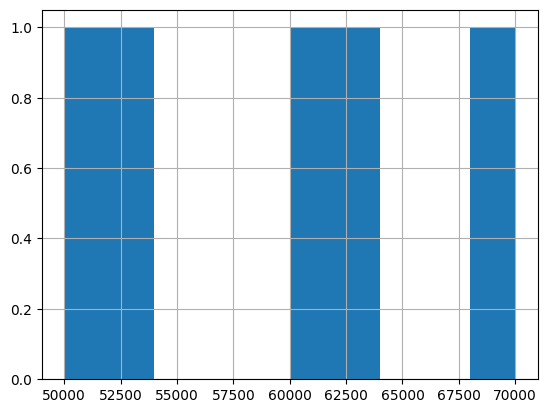

In [ ]:
df['Salary'].hist()

<Axes: >

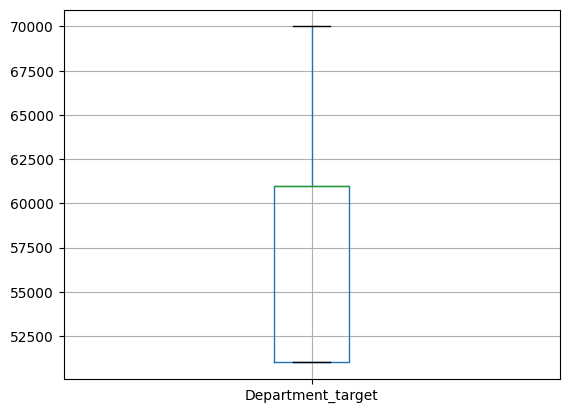

In [ ]:
df.boxplot(column=['Department_target'])

<Axes: xlabel='Salary', ylabel='Department_target'>

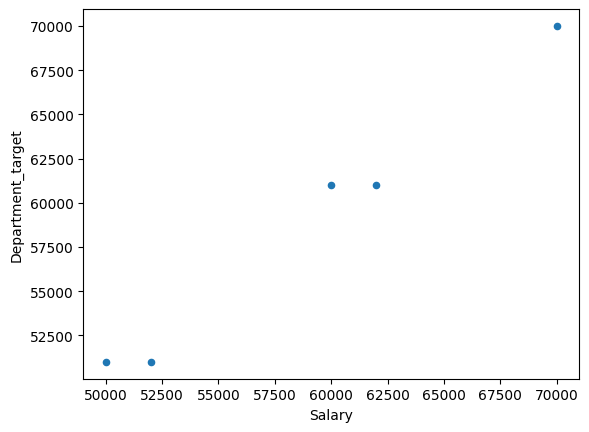

In [ ]:
df.plot.scatter(x='Salary', y='Department_target')

<Axes: xlabel='Salary'>

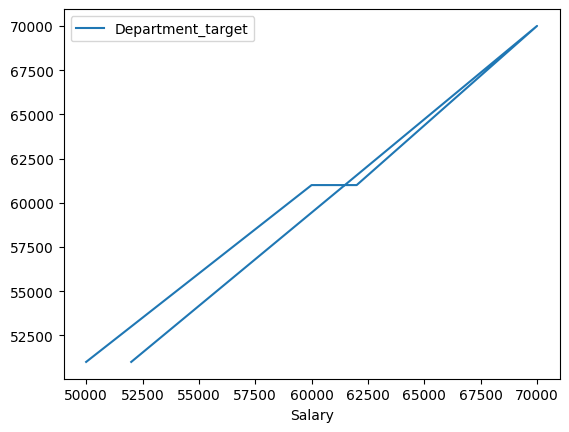

In [ ]:
df.plot.line(x='Salary', y='Department_target')